# Showcasing `nuctrans_fastuq.analysis.plots`

A hands-on tour of the five modules in `src/nuctrans_fastuq/analysis/plots/`, run against the
real case data in `datastore/`:

| Module | What it does |
|---|---|
| `category_map.py` | Loads the styled host-rock category map (GeoJSON + CSV rules) into a `MapData`. |
| `map_plot.py` | Draws a `MapData` onto a matplotlib `Axes`. |
| `stratigraphy_plot.py` | Loads a case's stratigraphic column into a `Site` and draws it. |
| `quantities_plot.py` | Draws quantity-vs-time / quantity-vs-depth panels, read from a surrogate's `propagation.h5` grid or a high-fidelity OGS ensemble file. |
| `compose_figure.py` | Composes map + stratigraphy + quantity panels into one figure, with connector lines. |

Each module also ships a markdown doc next to it (`MAP_PLOT.md`, `STRATIGRAPHY_PLOT.md`,
`QUANTITIES_PLOT.md`, `COMPOSE_FIGURE.md`) — treat those as the reference and this notebook as the
walkthrough. Their own quickstarts import from a package called `sitefig`; in this repo the same
code lives at `nuctrans_fastuq.analysis.plots`, so that's what's imported below.

**Real data used:**
- The bundled `map_data/` — Germany's host-rock categories (from BGE's published *Teilgebiete*
  site-selection report) and state outlines.
- `datastore/Case3_Claystone/9703b19a` — a generic North-German claystone repository model; I-129
  flux-ratio surrogate at the top/bottom of the host rock.
- `datastore/Case3_Claystone_release_rate/4324cbb3` — the same site, modelled for the total I-129
  release rate out of the host rock, with a real 100-run OGS ensemble alongside its surrogate.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np

from nuctrans_fastuq.analysis.plots.category_map import load_map
from nuctrans_fastuq.analysis.plots.map_plot import plot_map
from nuctrans_fastuq.analysis.plots.stratigraphy_plot import load_site, plot_stratigraphy, lithology_handles
from nuctrans_fastuq.analysis.plots.quantities_plot import (
    ensemble_from_surrogate, depth_profile_from_surrogate, ensemble_from_leakage,
    ensemble_from_high_fidelity, depth_profile_from_high_fidelity,
    QuantityPanel, DepthPanel, plot_quantity, plot_depth_profile,
)
from nuctrans_fastuq.analysis.plots.compose_figure import SiteBlock, Location, make_figure, Layout

# importing nuctrans_fastuq.analysis.plots.* above sets the matplotlib backend to Agg as a side
# effect (plots/__init__.py); switch to the inline backend afterwards so figures render below
%matplotlib inline

# repo root, whether this notebook runs from its own folder or from the repo root
REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "pyproject.toml").exists():
    if REPO_ROOT == REPO_ROOT.parent:
        raise RuntimeError(f"couldn't find pyproject.toml above {Path.cwd()} -- run this notebook from inside the nuctrans_fastuq repo")
    REPO_ROOT = REPO_ROOT.parent

MAP_DIR = REPO_ROOT / "src/nuctrans_fastuq/analysis/plots/map_data"

CASE1 = REPO_ROOT / "datastore/Case3_Claystone/9703b19a"
CASE1_SCENARIO = CASE1 / "decision_support/ccde36cd/analysis/33461778/scenario.yaml"
CASE1_PROPAGATION = CASE1 / "decision_support/ccde36cd/propagation.h5"
CASE1_OGS_ENSEMBLE = CASE1 / "model_results/ensemble_results_with_sample_random_size100_seed21.h5"

CASE2 = REPO_ROOT / "datastore/Case2_Claystone_uq_geometry/01b59098"
CASE2_SCENARIO = CASE2 / "decision_support/9da7e551/analysis/1d90f60c/scenario.yaml"
CASE2_PROPAGATION = CASE2 / "decision_support/9da7e551/propagation.h5"
CASE2_OGS_ENSEMBLE = (
    CASE2 / "model_results/ensemble_results_with_sample_random_size100_seed21.h5"
)

CASE3 = REPO_ROOT / "datastore/Case3_Claystone_release_rate/4324cbb3"
CASE3_SCENARIO = CASE3 / "decision_support/ea234f55/analysis/97ac8985/scenario.yaml"
CASE3_PROPAGATION = CASE3 / "decision_support/ea234f55/propagation.h5"
CASE3_OGS_ENSEMBLE = CASE3 / "model_results/ensemble_results_with_sample_random_size100_seed21.h5"

In [2]:
def show(fig):
    """Display a figure inline and close it (a bare Figure as a cell's last expression would otherwise
    display twice: once as the cell's result, once via matplotlib's inline auto-show).
    """
    display(fig)
    plt.close(fig)

In [3]:
OUT = Path("output2")


def save(fig, name):
    OUT.mkdir(exist_ok=True)
    # fig.savefig(OUT / f"{name}.png", dpi=600)
    fig.savefig(OUT / f"{name}.pdf")
    print("wrote", OUT / f"{name}")
    plt.close(fig)

## 1. `category_map.py` — loading the styled map

`load_map(map_dir)` reads `categories.geojson` + `outlines.geojson` (both lon/lat, EPSG:4326) and
styles the category polygons from `category_rules.csv` — a `(label, filter, color)` table where
`filter` is a small QGIS-style rule expression (`"Field" = 'value'`, `"Field" LIKE 'pattern%'`,
optionally `AND`-joined). Editing that CSV is enough to change what's drawn; no code changes
needed.

In [4]:
map_data = load_map(MAP_DIR)

print(
    f"{len(map_data.features)} category features, {len(map_data.outlines)} outline features"
)
print("categories:", map_data.style.labels)
print("bounds (lon, lat):", tuple(round(b, 2) for b in map_data.bounds))

90 category features, 34 outline features
categories: ['Crystalline host rock', 'Host rock salt', 'Host rock clay', 'Other']
bounds (lon, lat): (5.87, 47.27, 15.04, 55.1)


In [5]:
# DE_North_Claystone's tagged region (Lower Saxony) -- confirms the site really sits on clay host rock
example_loc = Location(7.6227, 52.709, "DE_North_Claystone", label_offset=(6, 6))
print(
    "map category at that point:",
    map_data.category_at(example_loc.lon, example_loc.lat),
)

map category at that point: Host rock clay


## 2. `map_plot.py` — drawing the map

`plot_map(ax, map_data, ...)` draws the category polygons and the outline layer, with the
lon/lat aspect ratio corrected automatically. `categories=` restricts what's drawn (and legended);
`extent=` crops/pads the view.

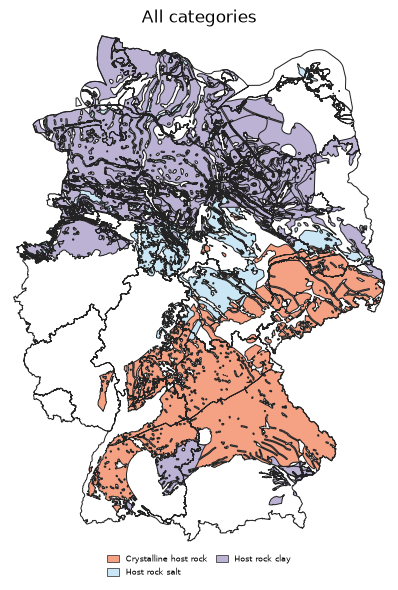

In [6]:
fig, ax = plt.subplots(figsize=(5, 6))
plot_map(ax, map_data)
ax.set_title("All categories")
fig.tight_layout()

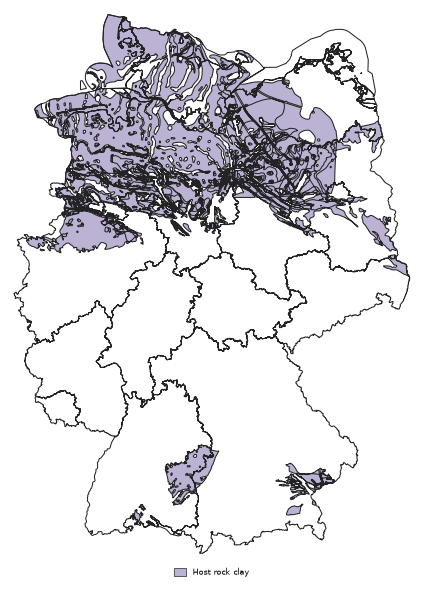

In [7]:
# only the clay categories
fig, ax = plt.subplots(figsize=(5, 6))
plot_map(ax, map_data, categories=["Host rock clay"])
fig.tight_layout()

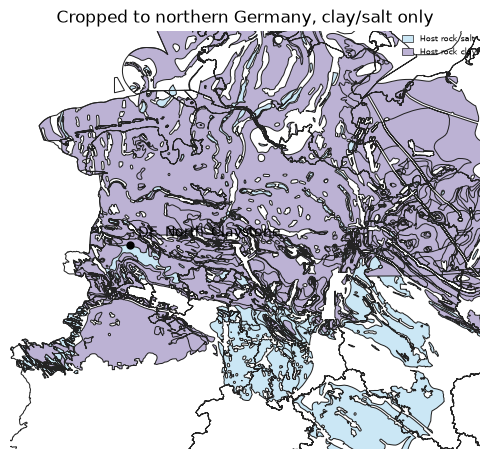

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_map(
    ax,
    map_data,
    categories=["Host rock clay", "Host rock salt"],
    extent=(6.0, 51.0, 12.5, 54.5),  # roughly northern Germany
    legend_loc="upper right",
)
ax.plot(example_loc.lon, example_loc.lat, "o", color="black", markersize=5)
ax.annotate(
    example_loc.label,
    (example_loc.lon, example_loc.lat),
    xytext=(6, 6),
    textcoords="offset points",
)
ax.set_title("Cropped to northern Germany, clay/salt only")
fig.tight_layout()

### show, save and adjust the layout with make_figure


`make_figure()` is the one entry point that doesn't draw an `Axes` of its own: it lays out a map,
one or more stratigraphy columns, and their quantity panels into a single figure, sizing
everything and drawing the dashed connector lines from a map location to its stratigraphy, and
from the stratigraphy to each panel's depth/zone.

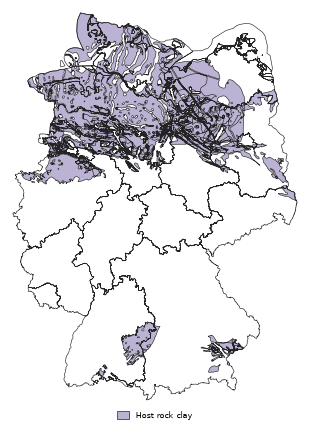

wrote output2/01_map_clay_only


In [9]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 180}
MM_PER_INCH = 25.4
figure_name = "01_map_clay_only"
show(make_figure([], map_data=map_data, categories=["Host rock clay"]))
save(
    make_figure(
        [],
        map_data=map_data,
        categories=["Host rock clay"],
        layout=Layout(width=NATURE_WIDTH_MM["1col"] / MM_PER_INCH),
    ),
    figure_name,
)

## 3. `stratigraphy_plot.py` — loading & drawing a site's stratigraphy

`load_site(case_dir, case_yaml=None, host_unit="Host_rock")` reads a case's `site_data/*.yaml`
(lithologies) and `geometry/rock_interface.yaml` (unit depths) into an ordered list of `Unit`s.

One `datastore/` wrinkle: each case lives under a content-hash directory
(`Case3_Claystone/9703b19a/`), not one matching `<case>.yaml` the way `load_site()`'s default
expects — so `case_yaml` has to be passed explicitly. It's also worth pointing `case_yaml` at the
*resolved* `scenario.yaml` under `decision_support/.../analysis/.../` rather than the bare
`params.yaml`: only the resolved version carries the `analysis:` block (`labels`, `qoi`) that
`quantities_plot.py` and this notebook use below.

In [10]:
site1 = load_site(CASE1, case_yaml=CASE1_SCENARIO)
site2 = load_site(CASE2, case_yaml=CASE2_SCENARIO)
site3 = load_site(CASE3, case_yaml=CASE3_SCENARIO)

print(site1.name, "-", [u.name for u in site1.units])
print(
    f"host unit: {site1.host.name} [{site1.host.top:g}, {site1.host.bottom:g}] m, lithologies={site1.host.lithologies}"
)
print("repository depth (point source, case 1):", site1.repository_depth)
print("repository depth (line source, case 2): ", site2.repository_depth)

DE_North_Claystone - ['Quaternary', 'Albian', 'Aptian', 'Host_rock', 'Valanginian_Wealden', 'Jurassic_Upper', 'Jurassic_Middle', 'Jurassic_Lower', 'Keuper', 'Buntsandstein_Muschelkalk', 'Zechstein', 'basement']
host unit: Host_rock [-400.01, -522.51] m, lithologies=['Mudstone', 'Limestone']
repository depth (point source, case 1): -462.5
repository depth (line source, case 2):  -462.5


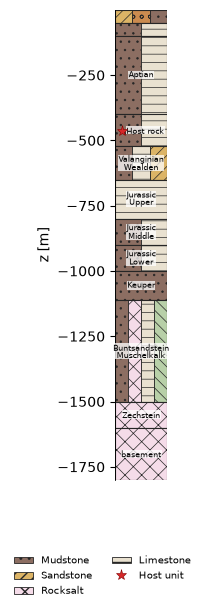

In [11]:
fig, ax = plt.subplots(figsize=(1.6, 5))
plot_stratigraphy(ax, site1, lithology_mode="split")
fig.legend(
    handles=lithology_handles([site1]),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
    frameon=False,
    fontsize=7,
)
fig.tight_layout()

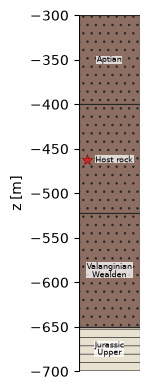

In [12]:
# z_limit crops the column to a depth window -- here, just around the host rock
fig, ax = plt.subplots(figsize=(1.6, 4))
plot_stratigraphy(ax, site1, z_limit=(-300, -700))
fig.tight_layout()

### show, save and adjust the layout with make_figure

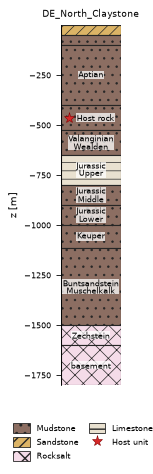

wrote output2/02_stratigraphy_only


In [13]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 180}
MM_PER_INCH = 25.4
figure_name = "02_stratigraphy_only"
show(make_figure([SiteBlock(site1)]))
save(
    make_figure(
        [SiteBlock(site1)],
        layout=Layout(width=NATURE_WIDTH_MM["1col"] / MM_PER_INCH),
    ),
    figure_name,
)

/Users/chenqian/nuctrans_fastuq/src/nuctrans_fastuq/analysis/plots/compose_figure.py:221: UserWarning: location_lines=True but no block has a location (lon, lat); no location lines drawn
  warnings.warn(


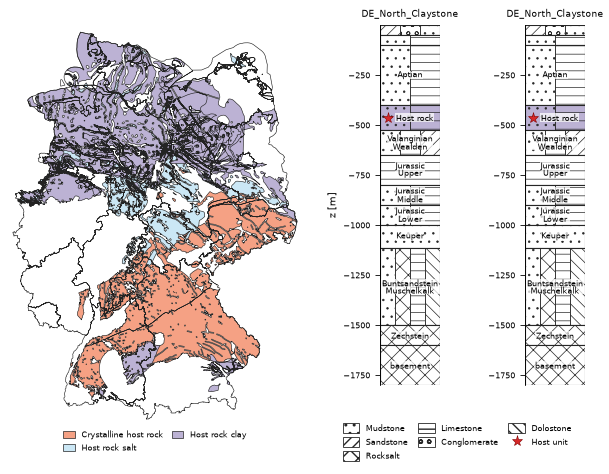

/Users/chenqian/nuctrans_fastuq/src/nuctrans_fastuq/analysis/plots/compose_figure.py:221: UserWarning: location_lines=True but no block has a location (lon, lat); no location lines drawn
  warnings.warn(


wrote output2/03_stratigraphy_map


In [14]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "03_stratigraphy_map"
show(
    make_figure(
        [SiteBlock(site1), SiteBlock(site1)],
        lithology_mode="split",
        map_data=map_data,
        show_map=True,
    )
)
save(
    make_figure(
        [SiteBlock(site1), SiteBlock(site1)],
        map_data=map_data,
        show_map=True,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

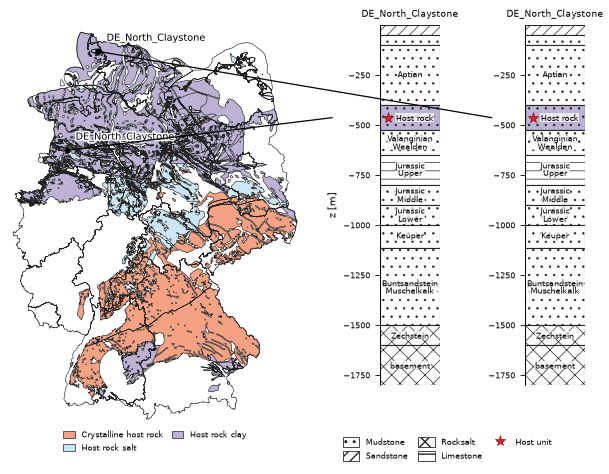

wrote output2/033_stratigraphy_map_location


In [15]:
# add location
example_loc = Location(7.6227, 52.709, "DE_North_Claystone", label_offset=(6, 6))
example_loc2 = Location(8.6227, 54.709, "DE_North_Claystone", label_offset=(6, 6))

NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "033_stratigraphy_map_location"
show(
    make_figure(
        [
            SiteBlock(site1, location=example_loc),
            SiteBlock(site1, location=example_loc2),
        ],
        map_data=map_data,
        show_map=True,
        location_lines=True,
    )
)
save(
    make_figure(
        [
            SiteBlock(site1, location=example_loc),
            SiteBlock(site1, location=example_loc2),
        ],
        map_data=map_data,
        show_map=True,
        location_lines=True,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

## 4. `quantities_plot.py` — time series and depth profiles

### 4a. Surrogate and OGS flux ratio at the host rock's top and bottom

`site.analysis["qoi"]` and `site.analysis["labels"]` come straight from the case's `analysis:`
block (loaded above via `scenario.yaml`): which nuclide/quantity/unit/factor/threshold to show, and
which named depths to evaluate. The flux ratio is signed -- it is the raw surrogate flux times
`qoi["factor"]` -- so the threshold line's sign flips between the top (flux flowing in) and the
bottom (flux flowing out) of the host rock.

### with depth's value

qoi: {'nuclide': 'I-129', 'quantity': 'Flux ratio', 'factor': 0.1, 'unit': '1/year', 'threshold': 1e-07}
depths: [-400, -522.5]


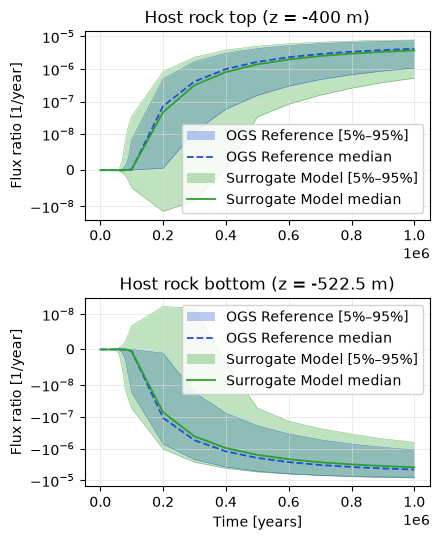

In [16]:
qoi1 = site1.analysis["qoi"]
depths = sorted(
    site1.analysis["labels"].values(), reverse=True
)  # shallowest (top) first
print("qoi:", qoi1)
print("depths:", depths)


panels1 = []
for z in depths:
    e_sur = ensemble_from_surrogate(
        CASE1_PROPAGATION,
        z,
        site=site1,
        factor=qoi1.get("factor", 1),
        label="Surrogate Model",
        unit=qoi1["unit"],
    )
    e_ogs = ensemble_from_high_fidelity(
        CASE1_OGS_ENSEMBLE,
        "I-129",
        "flux",
        z=z,
        site=site1,
        unit=e_sur.unit,
        label="OGS Reference",
    )
    panels1.append(
        QuantityPanel(
            [e_ogs, e_sur],
            depth=z,
            yscale="symlog",
            threshold=None,
            ylabel=f"{qoi1['quantity']} [{qoi1['unit']}]",
        )
    )

fig, axes = plt.subplots(2, 1, figsize=(4.5, 5.5))
plot_quantity(axes[0], panels1[0], site=site1, show_xlabel=False)
plot_quantity(axes[1], panels1[1], site=site1)
fig.tight_layout()

#### show with make_figure

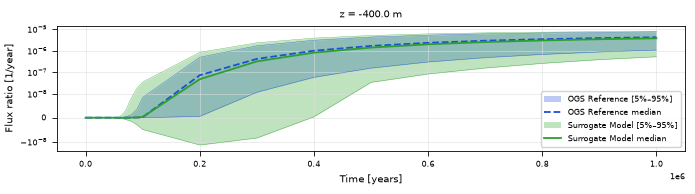

In [17]:
# one plots

show(make_figure([SiteBlock(panels=[panels1[0]])]))

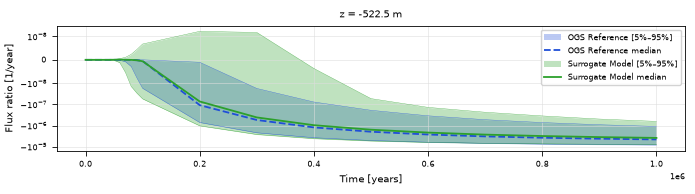

In [18]:
# one plots

show(make_figure([SiteBlock(panels=[panels1[1]])]))

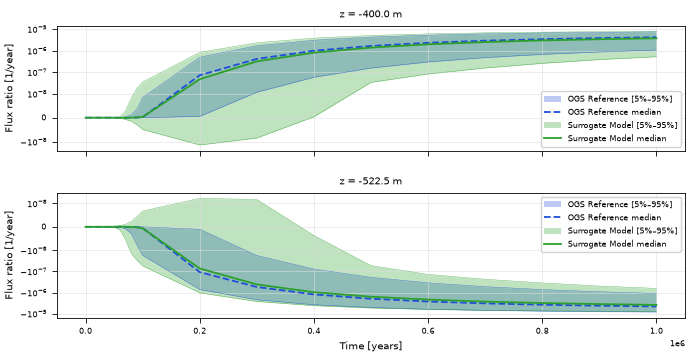

In [19]:
# two plots

show(make_figure([SiteBlock(panels=panels1)], quantity_legend="all"))

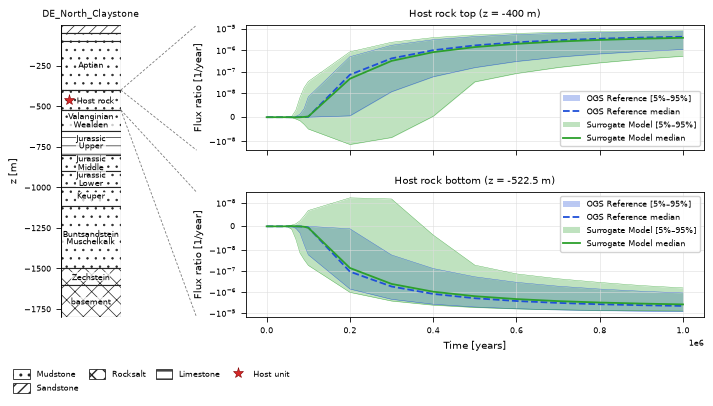

In [20]:
show(
    make_figure(
        [SiteBlock(site=site1, panels=panels1)],
        color_mode="host_only",
        quantity_legend="all",
        show_stratigraphy=True,
    )
)

### with a string for the depth

qoi: {'nuclide': 'I-129', 'quantity': 'Flux', 'unit': 'mol/(m² year)', 'threshold': 'None'}
depths: ['Host_rock_top', 'Host_rock_bottom']


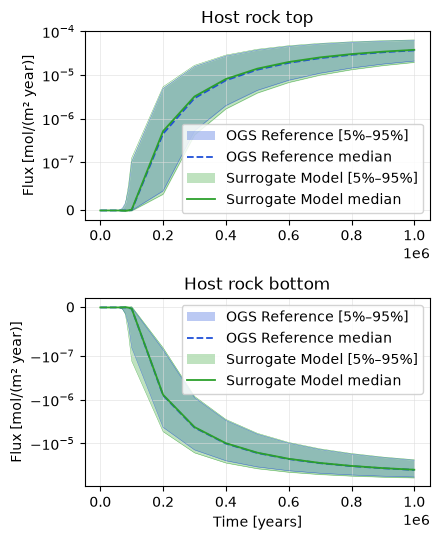

In [21]:
qoi2 = site2.analysis["qoi"]
depths = sorted(
    site2.analysis["labels"].values(), reverse=True
)  # shallowest (top) first
print("qoi:", qoi2)
print("depths:", depths)


panels2 = []
for z in ["Host_rock_top", "Host_rock_bottom"]:
    e_sur = ensemble_from_surrogate(
        CASE2_PROPAGATION,
        z,
        site=site2,
        factor=qoi2.get("factor", 1),
        label="Surrogate Model",
        unit=qoi2["unit"],
    )
    e_ogs = ensemble_from_high_fidelity(
        CASE2_OGS_ENSEMBLE,
        "I-129",
        "flux",
        z=z,
        site=site2,
        unit=e_sur.unit,
        label="OGS Reference",
    )
    panels2.append(
        QuantityPanel(
            [e_ogs, e_sur],
            depth=z,
            yscale="symlog",
            threshold=None,
            ylabel=f"{qoi2['quantity']} [{qoi2['unit']}]",
        )
    )

fig, axes = plt.subplots(2, 1, figsize=(4.5, 5.5))
plot_quantity(axes[0], panels2[0], site=site2, show_xlabel=False)
plot_quantity(axes[1], panels2[1], site=site2)
fig.tight_layout()

### show, save and adjust the layout with make_figure

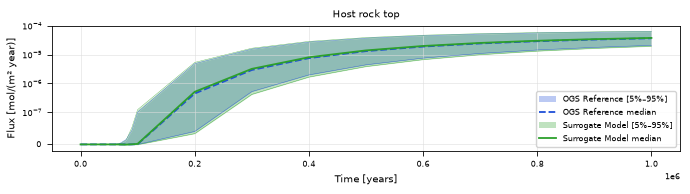

wrote output2/04_flux_top_only


In [22]:
# one plots
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "04_flux_top_only"
show(make_figure([SiteBlock(panels=[panels2[0]])]))
save(
    make_figure(
        [SiteBlock(panels=[panels2[0]])],
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

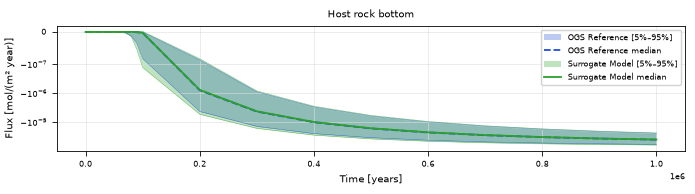

wrote output2/04_flux_bottom_only


In [23]:
# one plots
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "04_flux_bottom_only"
show(make_figure([SiteBlock(panels=[panels2[1]])]))
save(
    make_figure(
        [SiteBlock(panels=[panels2[1]])],
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

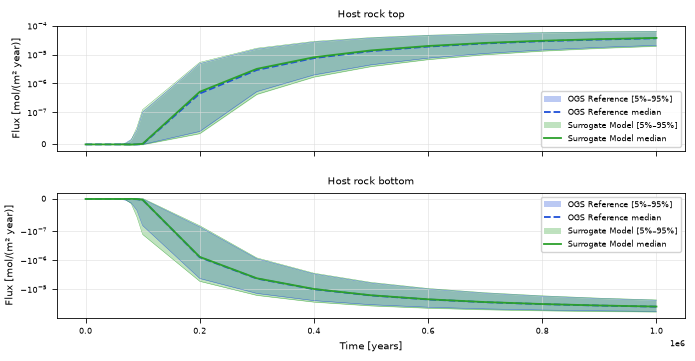

wrote output2/04_flux_only


In [24]:
# two plots
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "04_flux_only"
show(make_figure([SiteBlock(panels=panels2)], quantity_legend="all"))
save(
    make_figure(
        [SiteBlock(panels=panels2)],
        quantity_legend="all",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

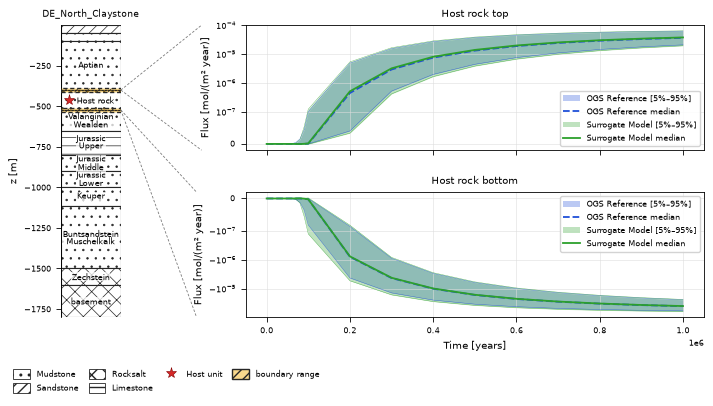

wrote output2/05_stratigraphy_flux


In [25]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "05_stratigraphy_flux"
show(
    make_figure(
        [SiteBlock(site=site2, panels=panels2)],
        color_mode="host_only",
        quantity_legend="all",
        show_stratigraphy=True,
    )
)
save(
    make_figure(
        [SiteBlock(site=site2, panels=panels2)],
        color_mode="host_only",
        quantity_legend="all",
        show_stratigraphy=True,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

/Users/chenqian/nuctrans_fastuq/src/nuctrans_fastuq/analysis/plots/compose_figure.py:221: UserWarning: location_lines=True but no block has a location (lon, lat); no location lines drawn
  warnings.warn(


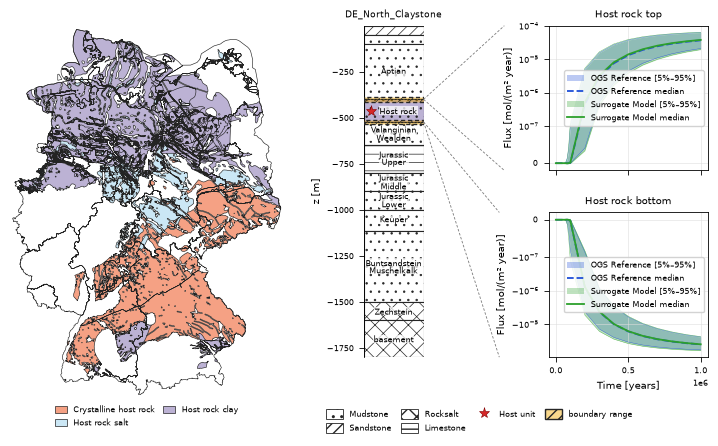

/Users/chenqian/nuctrans_fastuq/src/nuctrans_fastuq/analysis/plots/compose_figure.py:221: UserWarning: location_lines=True but no block has a location (lon, lat); no location lines drawn
  warnings.warn(


wrote output2/06_map_stratigraphy_flux


In [26]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "06_map_stratigraphy_flux"
show(
    make_figure(
        [SiteBlock(site=site2, panels=panels2)],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
    )
)
save(
    make_figure(
        [SiteBlock(site=site2, panels=panels2)],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

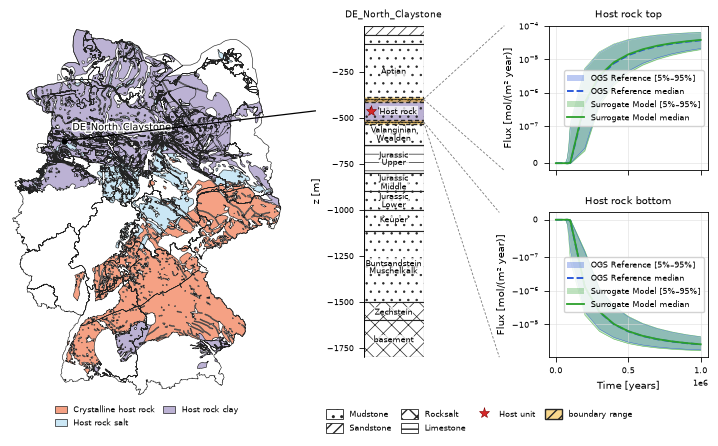

wrote output2/06_map_location_stratigraphy_flux


In [27]:
# add location
example_loc = Location(7.6227, 52.709, "DE_North_Claystone", label_offset=(6, 6))

NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "06_map_location_stratigraphy_flux"
show(
    make_figure(
        [SiteBlock(site=site2, panels=panels2, location=example_loc)],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
    )
)
save(
    make_figure(
        [SiteBlock(site=site2, panels=panels2, location=example_loc)],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

### compare case 1 with case 2 at Host rock top

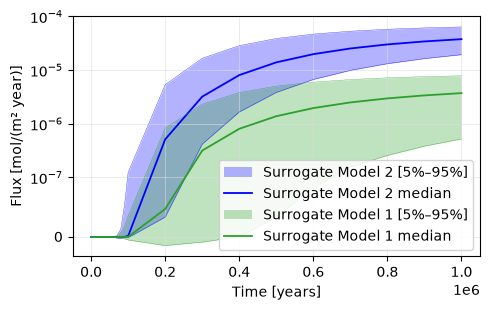

In [28]:
panel_flux_compare = []

e_sur_case2 = ensemble_from_surrogate(
    CASE2_PROPAGATION,
    depth="Host_rock_top",
    site=site2,
    factor=qoi2.get("factor", 1),
    label="Surrogate Model 2",
    unit=qoi2["unit"],
    color="b",
)

e_sur_case1 = ensemble_from_surrogate(
    CASE1_PROPAGATION,
    depth="Host_rock_top",
    site=site1,
    factor=qoi1.get("factor", 1),
    label="Surrogate Model 1",
    unit=qoi1["unit"],
)


panel_flux_compare = QuantityPanel(
    [e_sur_case2, e_sur_case1],
    yscale="symlog",
    threshold=None,
    ylabel=f"{qoi2['quantity']} [{qoi2['unit']}]",
)


fig, ax = plt.subplots(figsize=(5, 3.2))
plot_quantity(ax, panel_flux_compare)
fig.tight_layout()

### 4b. Surrogate vs. a real OGS ensemble

`ensemble_from_leakage()` reads a *zone*-integrated quantity (no single depth) straight out of a
high-fidelity simulation file's `simulation_results/<nuclide>_<kind>` group. The
`Case3_Claystone_release_rate` case has exactly that: a real 100-run OGS ensemble for the total
I-129 release rate out of the host rock, alongside the 10,000-sample PCE surrogate built from it --
a genuine surrogate-vs-high-fidelity validation, not synthetic data.

surrogate samples: (10000, 47) | OGS samples: (100, 47)
median release rate at t=1e6 yr -- surrogate: 1.69e-07, OGS: 1.82e-07 [1/year]


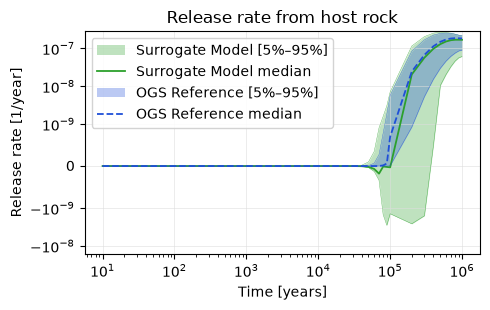

In [29]:
qoi3 = site3.analysis["qoi"]

e_surrogate = ensemble_from_surrogate(
    CASE3_PROPAGATION,
    depth=0.0,  # the `depth` argument above doesn't select anything on its own.
    factor=qoi3.get("factor", 1),
    unit=qoi3["unit"],
    label="Surrogate Model",
)
# this QoI is zone-integrated (no fixed depth), so axes/depth_z in propagation.h5 is a single
e_ogs = ensemble_from_leakage(
    CASE3_OGS_ENSEMBLE,
    zone="host rock",
    nuclide="total",
    kind="release_rate",
    label="OGS Reference",
)

print(
    "surrogate samples:", e_surrogate.values.shape, "| OGS samples:", e_ogs.values.shape
)
print(
    f"median release rate at t=1e6 yr -- surrogate: {np.nanmedian(e_surrogate.values, axis=0)[-1]:.3g}, "
    f"OGS: {np.nanmedian(e_ogs.values, axis=0)[-1]:.3g} [{qoi3['unit']}]"
)

panel_release = QuantityPanel(
    [e_surrogate, e_ogs],
    zone="Host_rock",
    xscale="log",
    yscale="symlog",
    ylabel=f"{qoi3['quantity']} [{qoi3['unit']}]",
    title="Release rate from host rock",
)
fig, ax = plt.subplots(figsize=(5, 3.2))
plot_quantity(ax, panel_release, site=site2)
fig.tight_layout()

### show, save and adjust the layout with make_figure

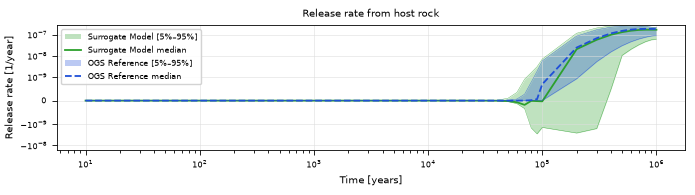

wrote output2/07_release_only


In [30]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_release_only"
show(make_figure([SiteBlock(panels=[panel_release])], quantity_legend="all"))
save(
    make_figure(
        [SiteBlock(panels=[panel_release])],
        quantity_legend="all",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

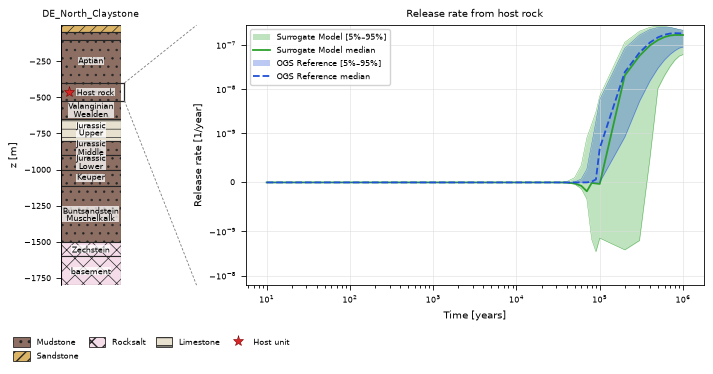

wrote output2/07_stratigraphy_release


In [31]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_stratigraphy_release"
show(
    make_figure(
        [SiteBlock(site=site3, panels=[panel_release])],
        color_mode="full",
        quantity_legend="all",
        show_stratigraphy=True,
    )
)
save(
    make_figure(
        [SiteBlock(site=site3, panels=[panel_release])],
        color_mode="full",
        quantity_legend="all",
        show_stratigraphy=True,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

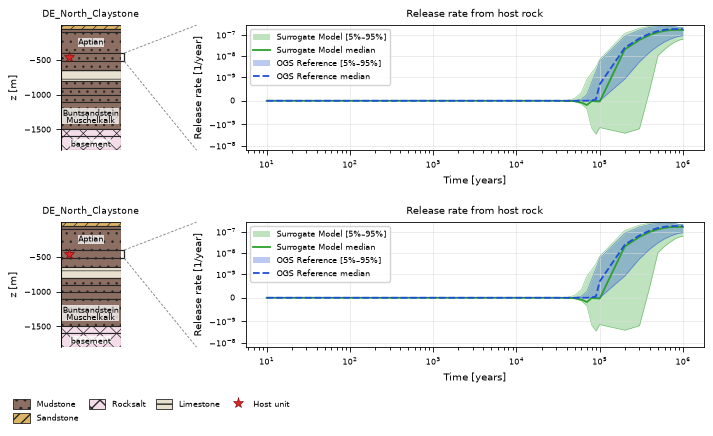

wrote output2/07_stratigraphy_release_compare


In [32]:
# compare
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_stratigraphy_release_compare"
show(
    make_figure(
        [
            SiteBlock(site=site3, panels=[panel_release]),
            SiteBlock(site=site3, panels=[panel_release]),
        ],
        color_mode="full",
        quantity_legend="all",
        show_stratigraphy=True,
        merge_stratigraphy=False,
    )
)
save(
    make_figure(
        [
            SiteBlock(site=site3, panels=[panel_release]),
            SiteBlock(site=site3, panels=[panel_release]),
        ],
        color_mode="full",
        quantity_legend="all",
        show_stratigraphy=True,
        merge_stratigraphy=False,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

/Users/chenqian/nuctrans_fastuq/src/nuctrans_fastuq/analysis/plots/compose_figure.py:221: UserWarning: location_lines=True but no block has a location (lon, lat); no location lines drawn
  warnings.warn(


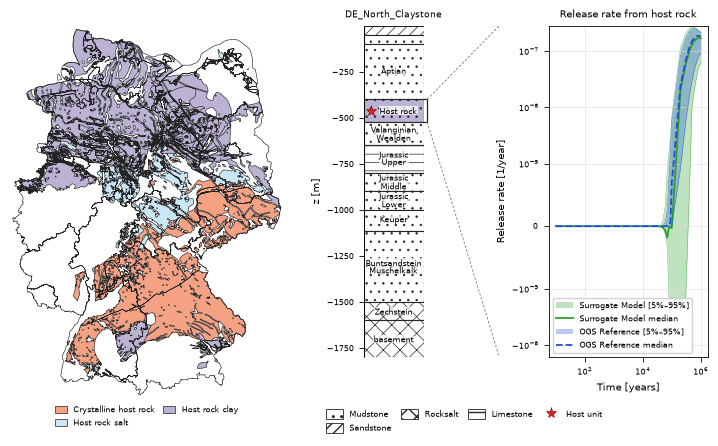

/Users/chenqian/nuctrans_fastuq/src/nuctrans_fastuq/analysis/plots/compose_figure.py:221: UserWarning: location_lines=True but no block has a location (lon, lat); no location lines drawn
  warnings.warn(


wrote output2/07_map_stratigraphy_release


In [33]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_map_stratigraphy_release"
show(
    make_figure(
        [SiteBlock(site=site3, panels=[panel_release])],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
    )
)
save(
    make_figure(
        [SiteBlock(site=site3, panels=[panel_release])],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

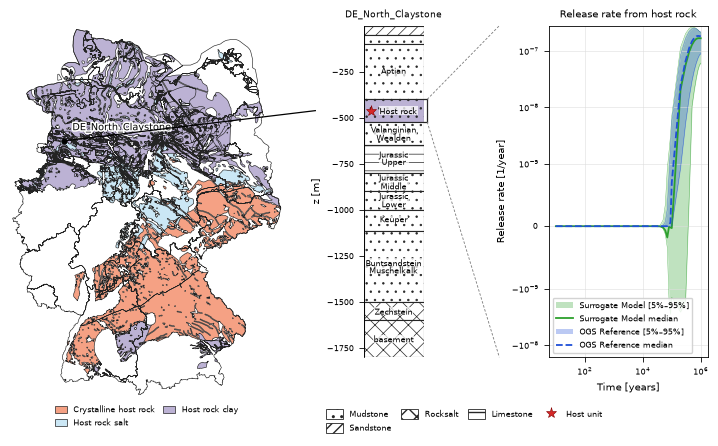

wrote output2/07_map_location_stratigraphy_release


In [34]:
# add location
example_loc = Location(7.6227, 52.709, "DE_North_Claystone", label_offset=(6, 6))

NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_map_location_stratigraphy_release"
show(
    make_figure(
        [SiteBlock(site=site3, panels=[panel_release], location=example_loc)],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
    )
)
save(
    make_figure(
        [SiteBlock(site=site3, panels=[panel_release], location=example_loc)],
        color_mode="host_only",
        show_stratigraphy=True,
        map_data=map_data,
        show_map=True,
        quantity_legend="all",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

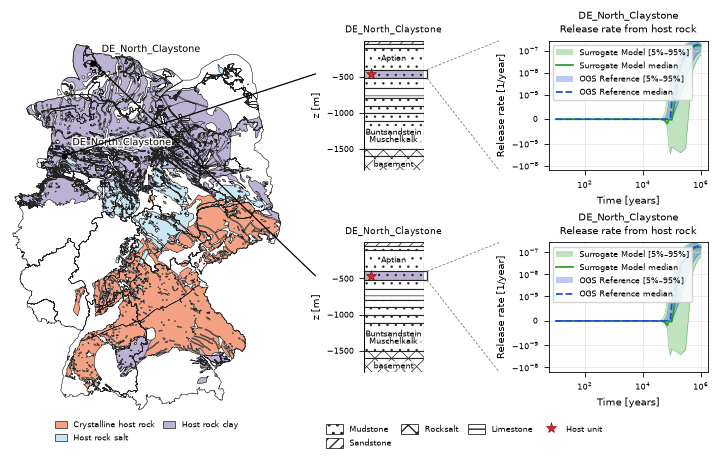

wrote output2/07_map_location_stratigraphy_release_compare


In [35]:
# compare with two locations:
example_loc = Location(7.6227, 52.709, "DE_North_Claystone", label_offset=(6, 6))

# compare
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_map_location_stratigraphy_release_compare"
show(
    make_figure(
        [
            SiteBlock(site=site3, panels=[panel_release], location=example_loc),
            SiteBlock(site=site3, panels=[panel_release], location=example_loc2),
        ],
        quantity_legend="all",
        show_stratigraphy=True,
        merge_stratigraphy=False,
        location_lines=True,
        map_data=map_data,
        show_map=True,
    )
)
save(
    make_figure(
        [
            SiteBlock(site=site3, panels=[panel_release], location=example_loc),
            SiteBlock(site=site3, panels=[panel_release], location=example_loc2),
        ],
        quantity_legend="all",
        show_stratigraphy=True,
        merge_stratigraphy=False,
        location_lines=True,
        map_data=map_data,
        show_map=True,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

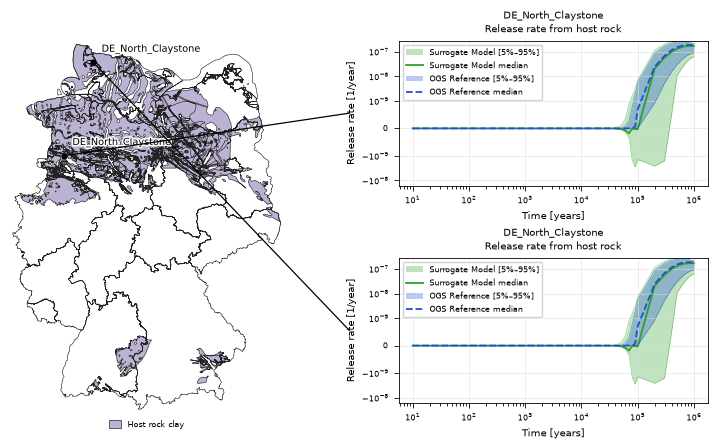

wrote output2/07_map_location_stratigraphy_release_compare


In [36]:
# compare with two locations:
example_loc = Location(7.6227, 52.709, "DE_North_Claystone", label_offset=(6, 6))

# compare
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "07_map_location_stratigraphy_release_compare"
show(
    make_figure(
        [
            SiteBlock(site=site3, panels=[panel_release], location=example_loc),
            SiteBlock(site=site3, panels=[panel_release], location=example_loc2),
        ],
        quantity_legend="all",
        show_stratigraphy=False,
        merge_stratigraphy=False,
        location_lines=True,
        map_data=map_data,
        show_map=True,
        categories=["Host rock clay"],
    )
)
save(
    make_figure(
        [
            SiteBlock(site=site3, panels=[panel_release], location=example_loc),
            SiteBlock(site=site3, panels=[panel_release], location=example_loc2),
        ],
        quantity_legend="all",
        show_stratigraphy=False,
        merge_stratigraphy=False,
        location_lines=True,
        map_data=map_data,
        show_map=True,
        categories=["Host rock clay"],
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    ),
    figure_name,
)

### 4c. Depth-resolved concentration


`depth_profile_from_surrogate()` is the depth-axis counterpart: fixed time, quantity vs. depth.
This case's surrogate was only built at the two depths of interest (`site.analysis["labels"]`), so
the profile below is honestly just two points -- `DepthPanel`/`plot_depth_profile()` handle that
the same way they'd handle a denser grid.

`depth_profile_from_high_fidelity()` read OGS ensemble, interpolating each sample onto a requested depth/time from its own finite mesh nodes. 

evaluated depths: [-522.51 -400.01] | time: 1000000.0 yr


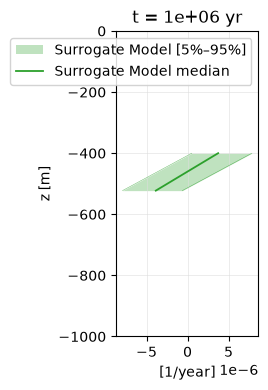

In [37]:
profile = depth_profile_from_surrogate(
    CASE1_PROPAGATION,
    time=1e6,
    factor=qoi1["factor"],
    unit=qoi1["unit"],
    label="Surrogate Model",
)
print("evaluated depths:", profile.depth, "| time:", profile.time, "yr")

depth_panel = DepthPanel(
    [profile], title=f"t = {profile.time:g} yr", z_limit=(0, -1000)
)
fig, ax = plt.subplots(figsize=(2.5, 4))
plot_depth_profile(ax, depth_panel)
fig.tight_layout()

depth nodes: (1891,)


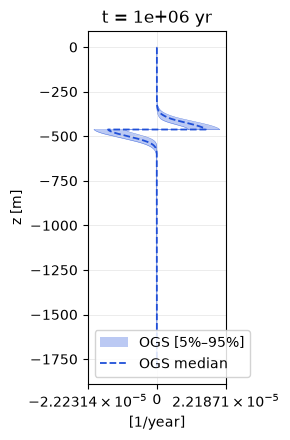

In [38]:
profile_hifi = depth_profile_from_high_fidelity(
    CASE1_OGS_ENSEMBLE, "I-129", "flux", time=1e6, site=site1, unit=qoi1["unit"]
)
print("depth nodes:", profile_hifi.depth.shape)

fig, ax = plt.subplots(figsize=(3, 4.5))
plot_depth_profile(
    ax,
    DepthPanel([profile_hifi], xscale="symlog", title=f"t = {profile_hifi.time:g} yr"),
)
fig.tight_layout()

### show, save and adjust the layout with make_figure

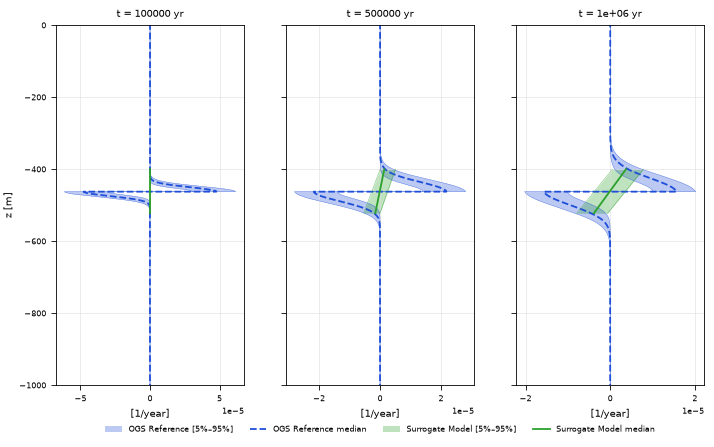

wrote output2/08_depth_only


In [39]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "08_depth_only"
conc_depth = [
    DepthPanel(
        [
            depth_profile_from_high_fidelity(
                CASE1_OGS_ENSEMBLE,
                "I-129",
                "flux",
                time=t,
                site=site1,
                unit=qoi1["unit"],
                label="OGS Reference",
            ),
            depth_profile_from_surrogate(
                CASE1_PROPAGATION,
                time=t,
                factor=qoi1["factor"],
                unit=qoi1["unit"],
                label="Surrogate Model",
            ),
        ],
        title=f"t = {t:g} yr",
        z_limit=(0, -1000),
    )
    for t in (1e5, 5e5, 1e6)
]

show(
    make_figure(
        [SiteBlock(depth_panels=conc_depth)],
        quantity_legend="bottom",
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH),
    )
)
save(
    make_figure([SiteBlock(depth_panels=conc_depth)], quantity_legend="bottom"),
    figure_name,
)

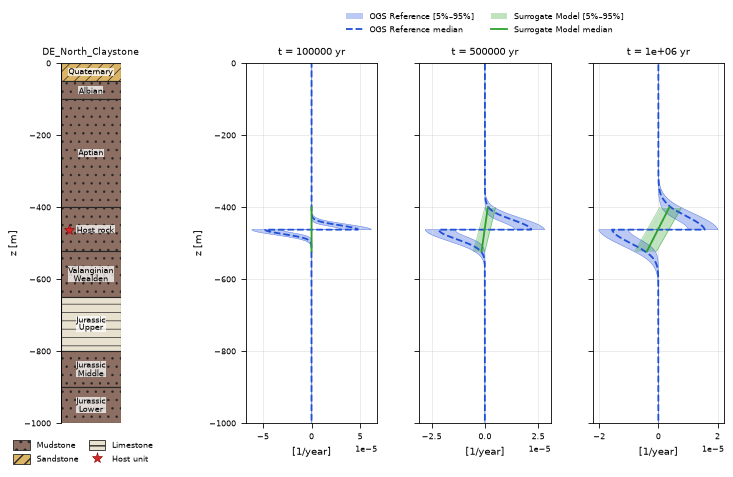

wrote output2/08_startigraphy_depth


In [ ]:
NATURE_WIDTH_MM = {"1col": 88, "2col": 188}
MM_PER_INCH = 25.4
figure_name = "08_startigraphy_depth"
conc_depth = [
    DepthPanel(
        [
            depth_profile_from_high_fidelity(
                CASE1_OGS_ENSEMBLE,
                "I-129",
                "flux",
                time=t,
                site=site1,
                unit=qoi1["unit"],
                label="OGS Reference",
            ),
            depth_profile_from_surrogate(
                CASE1_PROPAGATION,
                time=t,
                factor=qoi1["factor"],
                unit=qoi1["unit"],
                label="Surrogate Model",
            ),
        ],
        title=f"t = {t:g} yr",
    )
    for t in (1e5, 5e5, 1e6)
]

show(
    make_figure(
        [SiteBlock(site1, depth_panels=conc_depth, z_limit=(0, -1000))],
        color_mode="full",
        quantity_legend="top",
        quantity_legend_ncol=2,
        lithology_legend_ncol=2,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH, legend_height=0.1),
    )
)

save(
    make_figure(
        [SiteBlock(site1, depth_panels=conc_depth, z_limit=(0, -1000))],
        color_mode="full",
        quantity_legend="top",
        quantity_legend_ncol=2,
        lithology_legend_ncol=2,
        layout=Layout(width=NATURE_WIDTH_MM["2col"] / MM_PER_INCH, legend_height=0.1),
    ),
    figure_name,
)

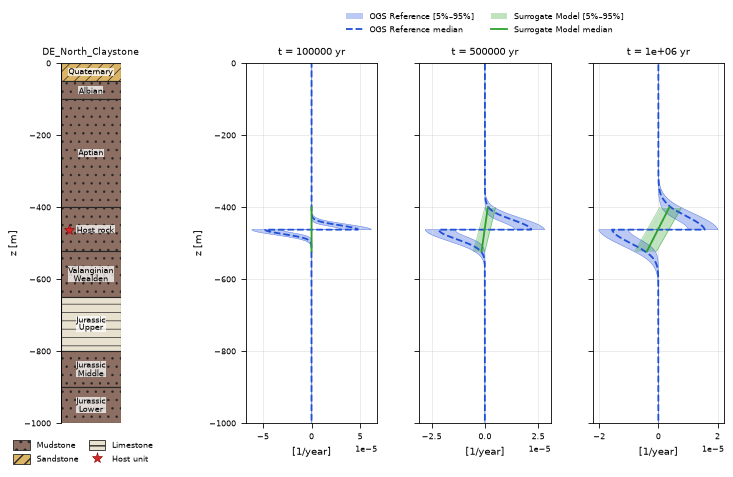